In [ ]:
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from google.colab.patches import cv2_imshow
from PIL import Image

In [ ]:
# Load and preprocess an example image
image_path = '/content/new as.jpg'
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
image = cv2.resize(image, (256, 256))
image = image / 255.0  # Normalize the pixel values to the range [0, 1]

# Define the CNN architecture
model = Sequential()

# First convolutional layer with ReLU activation and max pooling
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(256, 256, 1)))
model.add(MaxPooling2D((2, 2)))

# Second convolutional layer with ReLU activation and max pooling
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

# Third convolutional layer with ReLU activation and max pooling
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

# Flatten the output of the conv layers to feed into the dense layer
model.add(Flatten())

# Dense layer with ReLU activation
model.add(Dense(64, activation='relu'))

# Output layer with sigmoid activation (since edge detection can be treated as a binary classification problem)
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Summary of the model
model.summary()

# Reshape the image for input to the model
image = image.reshape(1, 256, 256, 1)

# Train the model (you can customize the number of epochs)
model.fit(image, np.array([1]), epochs=10)

# Perform edge detection
edge_map = model.predict(image)

# Post-process the edge map if necessary
edge_map = np.squeeze(edge_map)  # Remove the batch dimension

# Save the original image
cv2.imwrite('/content/original_image.jpg', (image[0, :, :, 0] * 255).astype(np.uint8))
cv2.imwrite('/content/original_image.jpg', (image[0, :, :, 0] * 255).astype(np.uint8))

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_38 (Conv2D)          (None, 254, 254, 32)      320       
                                                                 
 max_pooling2d_28 (MaxPooli  (None, 127, 127, 32)      0         
 ng2D)                                                           
                                                                 
 conv2d_39 (Conv2D)          (None, 125, 125, 64)      18496     
                                                                 
 max_pooling2d_29 (MaxPooli  (None, 62, 62, 64)        0         
 ng2D)                                                           
                                                                 
 conv2d_40 (Conv2D)          (None, 60, 60, 128)       73856     
                                                                 
 max_pooling2d_30 (MaxPooli  (None, 30, 30, 128)     

True

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
# Load an image
image = cv2.imread('/content/new as.jpg')

# Convert the image to RGB format
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Reshape the image to a 2D array of pixels and 3 color values (RGB)
pixel_values = image.reshape((-1, 3))

# Convert to float
pixel_values = np.float32(pixel_values)

# Define stopping criteria
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

# Number of clusters (K)
k = 3

# Perform K-means clustering
_, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Convert back to 8-bit pixel values
centers = np.uint8(centers)

# Flatten the labels array
labels = labels.flatten()

# Create the segmented image
segmented_image = centers[labels.flatten()]

# Reshape back to the original image dimension
segmented_image = segmented_image.reshape(image.shape)

# Convert the segmented image to grayscale
segmented_gray = cv2.cvtColor(segmented_image, cv2.COLOR_RGB2GRAY)

# Apply edge detection using the Canny method
edges = cv2.Canny(segmented_gray, 100, 200)

In [ ]:

# Display the original image, segmented image, and edge detected image
cv2.imwrite('edges.png', edges)

True

In [ ]:
import cv2
import numpy as np

# Load an image
image = cv2.imread('/content/new as.jpg')

# Convert the image to RGB format
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Reshape the image to a 2D array of pixels and 3 color values (RGB)
pixel_values = image.reshape((-1, 3))

# Convert to float
pixel_values = np.float32(pixel_values)

# Define stopping criteria
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

# Number of clusters (K)
k = 3

# Perform K-means clustering
_, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Convert back to 8-bit pixel values
centers = np.uint8(centers)

# Flatten the labels array
labels = labels.flatten()

# Create the segmented image
segmented_image = centers[labels.flatten()]

# Reshape back to the original image dimension
segmented_image = segmented_image.reshape(image.shape)

# Convert the segmented image to grayscale
segmented_gray = cv2.cvtColor(segmented_image, cv2.COLOR_RGB2GRAY)

# Apply threshold to the segmented image
_, segmented_thresh = cv2.threshold(segmented_gray, 127, 255, cv2.THRESH_BINARY)

# Apply edge detection using the Canny method with adjustable thickness
edges = cv2.Canny(segmented_thresh, 100, 200, apertureSize=3)

# Save the edge image as a PNG file
cv2.imwrite('edges0.png', edges)

# Display the original image, segmented image, thresholded image, and edge detected image
cv2.imwrite('edges2.png',image)
cv2.imwrite('edges3.png',segmented_image)
cv2.imwrite('edges4.png',  segmented_thresh)

# Wait for a key press and close the image window
cv2.waitKey(0)
cv2.destroyAllWindows()

In [ ]:
import cv2
import numpy as np

# Load an image
image = cv2.imread('/content/a2.jpg')

# Convert the image to RGB format
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Reshape the image to a 2D array of pixels and 3 color values (RGB)
pixel_values = image.reshape((-1, 3))

# Convert to float
pixel_values = np.float32(pixel_values)

# Define stopping criteria
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

# Number of clusters (K)
k = 3

# Perform K-means clustering
_, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Convert back to 8-bit pixel values
centers = np.uint8(centers)

# Flatten the labels array
labels = labels.flatten()

# Create the segmented image
segmented_image = centers[labels.flatten()]

# Reshape back to the original image dimension
segmented_image = segmented_image.reshape(image.shape)

# Convert the segmented image to grayscale
segmented_gray = cv2.cvtColor(segmented_image, cv2.COLOR_RGB2GRAY)

# Apply threshold to the segmented image
_, segmented_thresh = cv2.threshold(segmented_gray, 127, 255, cv2.THRESH_BINARY)

# Apply edge detection using the Canny method with adjustable thickness
edges = cv2.Canny(segmented_thresh, 100, 200, apertureSize=3)

# Apply Sobel filters to the segmented image
sobel_x = cv2.Sobel(segmented_gray, cv2.CV_64F, 1, 0, ksize=5)
sobel_y = cv2.Sobel(segmented_gray, cv2.CV_64F, 0, 1, ksize=5)

# Calculate the gradient magnitude and direction
gradient_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)
gradient_direction = np.arctan(sobel_y / sobel_x) * 180 / np.pi

# Apply threshold to the gradient magnitude
_, gradient_magnitude_thresh = cv2.threshold(gradient_magnitude, 50, 255, cv2.THRESH_BINARY)

# Apply threshold to the gradient direction
_, gradient_direction_thresh = cv2.threshold(gradient_direction, 45, 255, cv2.THRESH_BINARY)

# Combine the gradient magnitude and direction thresholds
edge_sobel = cv2.bitwise_and(gradient_magnitude_thresh, gradient_direction_thresh)

cv2.imwrite('edges5.png',   image)
cv2.imwrite('edges6.png',  segmented_image)
cv2.imwrite('edges7.png',   sobel_x)
cv2.imwrite('edges8.png',   sobel_y)
cv2.imwrite('edges9.png',  edges)
cv2.imwrite('edges10.png',  edge_sobel)


<ipython-input-27-1cbb0632f38f>:52: RuntimeWarning: divide by zero encountered in divide
  gradient_direction = np.arctan(sobel_y / sobel_x) * 180 / np.pi
<ipython-input-27-1cbb0632f38f>:52: RuntimeWarning: invalid value encountered in divide
  gradient_direction = np.arctan(sobel_y / sobel_x) * 180 / np.pi


True

In [ ]:
import cv2
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Read the input image
input_image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)
# Define the ground truth edges image
ground_truth_edges = cv2.imread('/content/binary_edge_image.jpg', cv2.IMREAD_GRAYSCALE)

# Calculate the gradient magnitude and direction
sobel_x = cv2.Sobel(input_image, cv2.CV_64F, 1, 0, ksize=5)
sobel_y = cv2.Sobel(input_image, cv2.CV_64F, 0, 1, ksize=5)


# Resize the input image to match the ground truth
input_image = cv2.resize(input_image, (ground_truth_edges.shape[1], ground_truth_edges.shape[0]))

# Resize or crop thresholded images to match the ground truth
gradient_magnitude_thresh = cv2.resize(gradient_magnitude_thresh, (ground_truth_edges.shape[1], ground_truth_edges.shape[0]))
gradient_direction_thresh = cv2.resize(gradient_direction_thresh, (ground_truth_edges.shape[1], ground_truth_edges.shape[0]))

# Threshold the ground truth edges image
_, ground_truth_edges = cv2.threshold(ground_truth_edges, 127, 200, cv2.THRESH_BINARY)

# Threshold the gradient magnitude thresholded image
_, gradient_magnitude_thresh = cv2.threshold(gradient_magnitude_thresh, 127, 200, cv2.THRESH_BINARY)

# Calculate the true positives, false positives, and false negatives
tp = np.count_nonzero(np.logical_and(ground_truth_edges, gradient_magnitude_thresh))
fp = np.count_nonzero(np.logical_and(np.logical_not(ground_truth_edges), gradient_magnitude_thresh))
fn = np.count_nonzero(np.logical_and(ground_truth_edges, np.logical_not(gradient_magnitude_thresh)))

# Calculate the precision, recall, and F1 score
# Calculate the precision, recall, and F1 score with pos_label=200
precision = precision_score(ground_truth_edges.flatten(), gradient_magnitude_thresh.flatten(), pos_label=200)
recall = recall_score(ground_truth_edges.flatten(), gradient_magnitude_thresh.flatten(), pos_label=200)
f1 = f1_score(ground_truth_edges.flatten(), gradient_magnitude_thresh.flatten(), pos_label=200)


print(f'Precision: {precision:.3f}')
print(f'Recall: {recall:.3f}')
print(f'F1 score: {f1:.3f}')

Precision: 0.281
Recall: 0.837
F1 score: 0.421


Color-Based Edge Detection (Channel-wise):
In color images, you can perform edge detection separately in individual color channels (e.g., RGB) and then combine the results to obtain color-based edge detection. Here's an example using OpenCV to perform edge detection in the red channel:

In [ ]:
import cv2
import numpy as np

# Load a color image
image = cv2.imread('/content/a2.jpg')

# Extract the red channel
red_channel = image[:, :, 2]

# Apply edge detection to the red channel (e.g., using Canny)
edges_red = cv2.Canny(red_channel, 100, 200)

# Display the edge-detected red channel
cv2.imwrite('edges12.png',  edges_red)
cv2.waitKey(0)
cv2.destroyAllWindows()


Histogram-Based Methods (Otsu's Thresholding):
Otsu's method is used for threshold selection. Here's an example using OpenCV:

In [ ]:
import cv2

# Load a grayscale image
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Apply Otsu's thresholding
_, thresholded = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Display the thresholded image
cv2.imwrite('edges13.png',  thresholded)
cv2.waitKey(0)
cv2.destroyAllWindows()

Texture Analysis:
Texture analysis can involve various methods. Here's an example using Haralick texture features with the mahotas library:

In [ ]:
!pip install mahotas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 15.1 MB/s eta 0:00:00


In [ ]:
import cv2
import mahotas as mh

# Load a grayscale image
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Calculate Haralick texture features
features = mh.features.haralick(image).mean(axis=0)

# Display texture features (can be used for texture-based edge detection)
print("Haralick Texture Features:")
print(features)


Haralick Texture Features:
[ 8.53838738e-03  1.02861098e+02  9.91795365e-01  6.26845477e+03
  8.44053095e-01  1.76754129e+02  2.49709580e+04  8.03523269e+00
  8.91834184e+00  2.35682429e-03  1.41081866e+00 -7.97065290e-01
  9.99996210e-01]



The output you provided represents the Haralick texture features extracted from an image using the Haralick texture analysis method. Each value in the array corresponds to a specific texture feature. Here's a brief explanation of each feature:

Angular Second Moment (ASM): 8.53838738e-03

It measures the uniformity of the image. Smaller values indicate more texture variation.
Contrast: 1.02861098e+02

Contrast measures the difference in intensity between a pixel and its neighbor over the entire image. Higher values suggest greater local variations.
Correlation: 9.91795365e-01

Correlation indicates how correlated the pixel values are with their neighbors. Values close to 1 suggest strong correlation.
Variance: 6.26845477e+03

Variance measures the spread of intensity values. Higher values indicate more texture variation.
Inverse Difference Moment (IDM): 8.44053095e-01

IDM quantifies the local homogeneity of the image. Higher values imply greater homogeneity.
Sum of Squares Variance (SSV): 1.76754129e+02

SSV measures the variability of the image intensity. Higher values indicate greater variation.
Sum Average (SASM): 2.49709580e+04

SASM quantifies the average sum of gray levels for pairs of pixels with different gray levels.
Sum Entropy (SENT): 8.03523269e+00

SENT measures the randomness of the image. Higher values indicate greater randomness.
Entropy: 8.91834184e+00

Entropy quantifies the amount of information or disorder in the image. Higher values suggest more complex textures.
Difference Variance (DVAR): 2.35682429e-03

DVAR measures the difference in intensity between a pixel and its neighbor. Smaller values indicate more uniform textures.
Difference Entropy (DENT): 1.41081866e+00

DENT quantifies the randomness of the differences between neighboring pixel intensities.
Information Measure of Correlation 1 (IMC1): -7.97065290e-01

IMC1 measures the degree of linear dependency between the marginal distributions of two different image regions.
Information Measure of Correlation 2 (IMC2): 9.99996210e-01

IMC2 is another measure of the degree of linear dependency between the marginal distributions of two different image regions.
These Haralick texture features are used for characterizing the texture properties of an image. The specific values obtained for each feature depend on the content and texture patterns present in the analyzed image. These features can be used for various applications such as texture classification, image segmentation, and object recognition, where texture information is valuable.

Multi-Scale and Multi-Resolution Approaches:
Combining edge detection results from different scales or resolutions can enhance edge detection. Here's an example using the Laplacian of Gaussian (LoG) at multiple scales:

In [ ]:
import cv2

# Load a grayscale image
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Define a list of scales (sigma values for LoG)
scales = [1, 2, 3]

# Perform edge detection at different scales
edges_multi_scale = []
for scale in scales:
    blurred = cv2.GaussianBlur(image, (0, 0), sigmaX=scale)
    edges = cv2.Laplacian(blurred, cv2.CV_64F)
    edges_multi_scale.append(edges)

# Combine edge maps (e.g., using maximum or weighted combination)
combined_edges = np.max(edges_multi_scale, axis=0)

# Display the combined edge map
cv2.imwrite('edges14.png', combined_edges)
cv2.waitKey(0)
cv2.destroyAllWindows()


In [ ]:
import cv2
import numpy as np

# Load a grayscale image
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Define a list of scales (sigma values for LoG)
scales = [1, 2, 3]

# Perform edge detection at different scales
edges_multi_scale = []
for scale in scales:
    blurred = cv2.GaussianBlur(image, (0, 0), sigmaX=scale)
    edges = cv2.Laplacian(blurred, cv2.CV_64F)
    edges_multi_scale.append(edges)

# Combine edge maps using maximum
combined_edges = np.max(edges_multi_scale, axis=0)

# Normalize the combined edge map to [0, 255]
normalized_edges = cv2.normalize(combined_edges, None, 0, 255, cv2.NORM_MINMAX)

# Apply threshold to make edges more visible (adjust threshold_value as needed)
threshold_value = 50
_, thresholded_edges = cv2.threshold(normalized_edges.astype(np.uint8), threshold_value, 255, cv2.THRESH_BINARY)

# Display the thresholded edge map
cv2.imwrite('edges15.png', thresholded_edges)
cv2.waitKey(0)
cv2.destroyAllWindows()


Overlaying Histograms:
You can overlay histograms on images to visualize the distribution of pixel values:

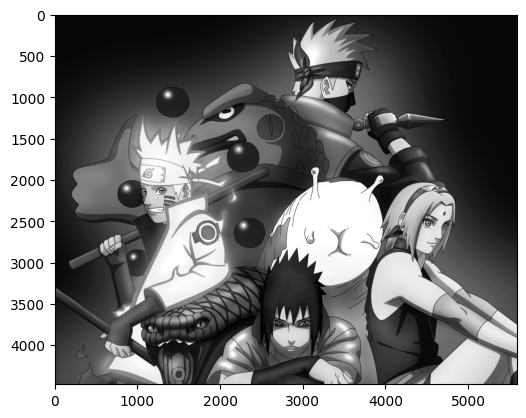

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load an image
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Plot a histogram on the image
plt.hist(image.ravel(), bins=256, range=(0, 256), density=True, color='blue', alpha=0.7)

# Display the image with the histogram
plt.imshow(image, cmap='gray')
plt.show()


Contour Plotting:
Use contour plots to visualize level curves or contours on images:

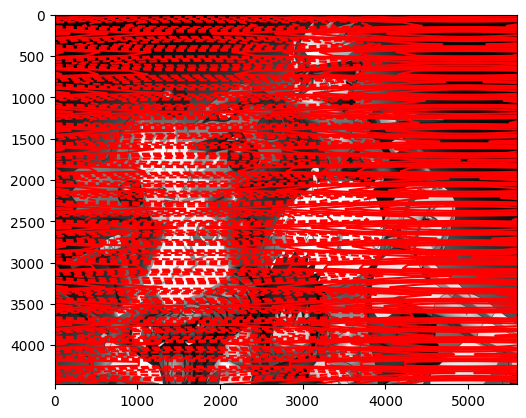

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load an image
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Create data for contour plot
x = np.linspace(0, image.shape[1], 100)
y = np.linspace(0, image.shape[0], 100)
X, Y = np.meshgrid(x, y)
Z = np.sin(X) + np.cos(Y)

# Plot contours on the image
plt.contour(X, Y, Z, levels=10, colors='red')

# Display the image with contours
plt.imshow(image, cmap='gray')
plt.show()


Heatmaps:
Generate and overlay heatmaps on images to represent intensity or density information:

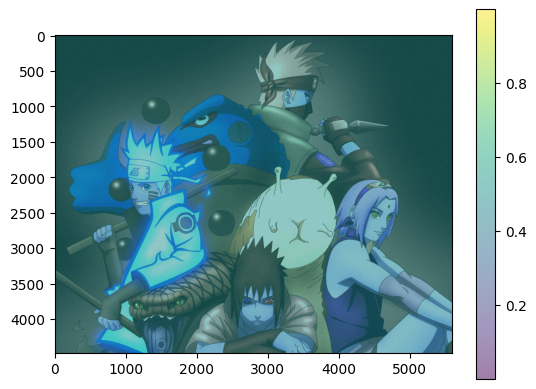

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load an image
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_COLOR)

# Create a heatmap data
heatmap = np.random.rand(image.shape[0], image.shape[1])

# Overlay the heatmap on the image
plt.imshow(image)
plt.imshow(heatmap, alpha=0.5, cmap='viridis', interpolation='bilinear')
plt.colorbar()
plt.show()


catter Plots:
Visualize scatter plots on images to represent data points or coordinates:

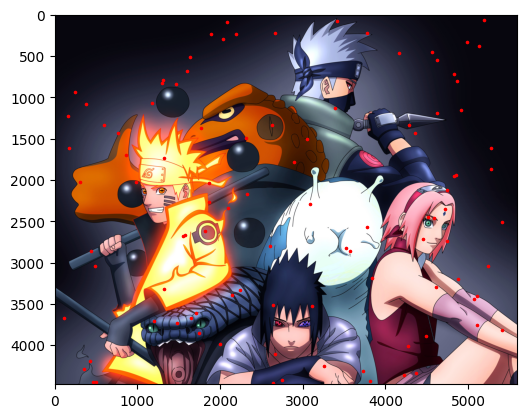

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load an image
image = cv2.imread('/content/a2.jpg')

# Generate random data points
x = np.random.randint(0, image.shape[1], size=100)
y = np.random.randint(0, image.shape[0], size=100)

# Plot the data points on the image
plt.scatter(x, y, c='red', marker='.', s=10)

# Display the image with scatter plot
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.show()


Bar Charts:
Create bar charts or bar graphs overlaid on images to represent data with bars:

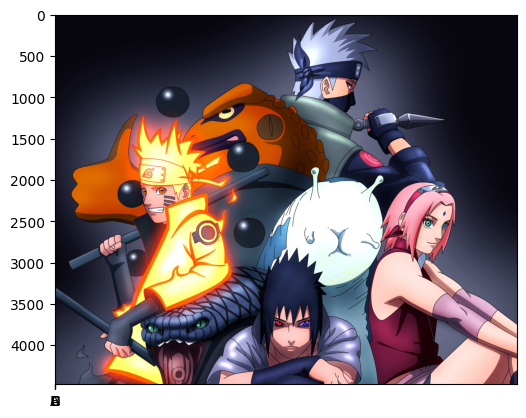

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load an image
image = cv2.imread('/content/a2.jpg')

# Define data for the bar chart
categories = ['A', 'B', 'C', 'D']
values = [10, 20, 15, 30]

# Plot a bar chart on the image
plt.bar(categories, values, color='blue')

# Display the image with the bar chart
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.show()


Text and Annotations:
You can add text, labels, and annotations to images using Matplotlib's text functions:

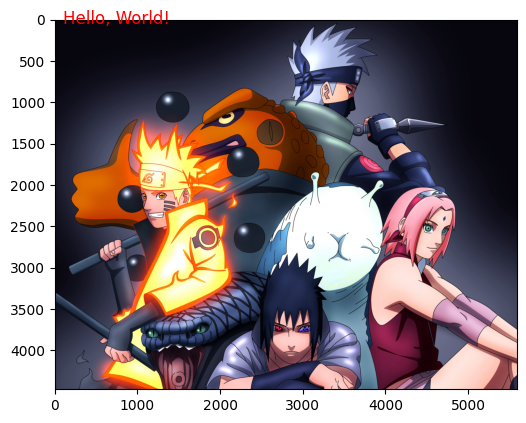

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load an image
image = cv2.imread('/content/a2.jpg')

# Add text to the image
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.text(100, 50, 'Hello, World!', fontsize=12, color='red')
plt.show()


Network Graph Visualization:
Visualize networks or graphs using NetworkX and Matplotlib. In this example, we'll create a simple graph and visualize it:

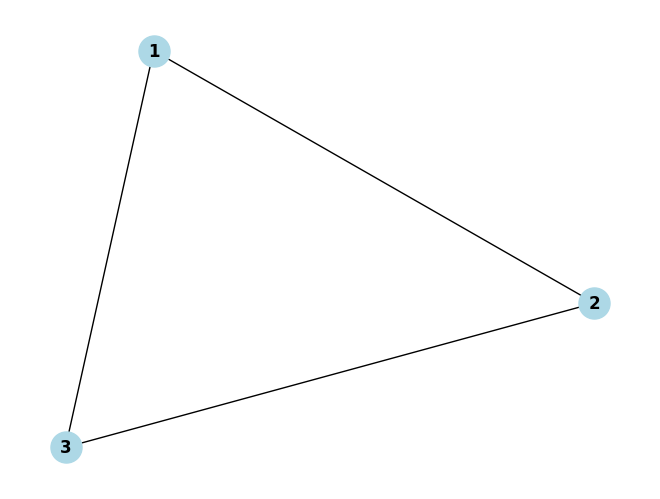

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a graph
G = nx.Graph()

# Add nodes
G.add_node(1)
G.add_node(2)
G.add_node(3)

# Add edges
G.add_edge(1, 2)
G.add_edge(2, 3)
G.add_edge(3, 1)

# Visualize the graph
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_color='lightblue', font_weight='bold', node_size=500)
plt.show()


Graph Layout and Visualization:
Customize the layout and style of a graph visualization using NetworkX and Matplotlib

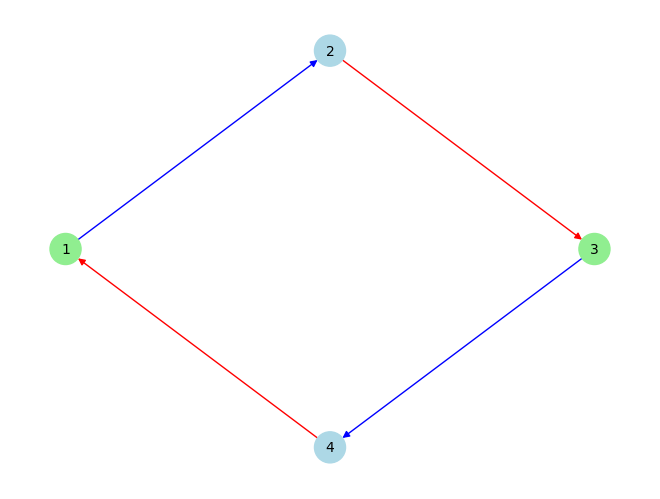

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a graph
G = nx.DiGraph()

# Add nodes and edges
G.add_nodes_from([1, 2, 3, 4])
G.add_edges_from([(1, 2), (2, 3), (3, 4), (4, 1)])

# Define node positions
pos = {1: (0, 0), 2: (1, 1), 3: (2, 0), 4: (1, -1)}

# Customize node and edge styles
node_colors = ['lightblue' if node % 2 == 0 else 'lightgreen' for node in G.nodes]
edge_colors = ['red' if edge[0] % 2 == 0 else 'blue' for edge in G.edges]

# Visualize the customized graph
nx.draw(G, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors, node_size=500, font_size=10)
plt.show()


Hierarchical Graph Visualization:
Visualize hierarchical structures using the pydot library. In this example, we'll visualize a simple tree structure:

In [ ]:
import pydot

# Create a directed graph
graph = pydot.Dot(graph_type='digraph')

# Add nodes
nodes = [pydot.Node(str(i), label=f'Node {i}') for i in range(1, 6)]
for node in nodes:
    graph.add_node(node)

# Add edges (hierarchical structure)
for i in range(1, 5):
    graph.add_edge(pydot.Edge(nodes[i - 1], nodes[i]))

# Visualize the hierarchical graph
graph.write_png('hierarchical_graph.png')


Complex Network Visualization:
Visualize complex networks using specialized libraries like Plotly. This example shows a visualization of a random network:

In [ ]:
import plotly.graph_objs as go
import networkx as nx
import plotly.offline as pyo

# Create a random graph
G = nx.random_geometric_graph(100, 0.125)

# Visualize the network using Plotly
pos = nx.get_node_attributes(G, 'pos')
edge_trace = go.Scatter(
    x=[],
    y=[],
    line=dict(width=0.5, color='#888'),
    hoverinfo='none',
    mode='lines')

for edge in G.edges():
    x0, y0 = pos[edge[0]]
    x1, y1 = pos[edge[1]]
    edge_trace['x'] += tuple([x0, x1, None])
    edge_trace['y'] += tuple([y0, y1, None])

node_trace = go.Scatter(
    x=[],
    y=[],
    text=[],
    mode='markers',
    hoverinfo='text',
    marker=dict(
        showscale=True,
        colorscale='YlGnBu',
        size=10,
        colorbar=dict(
            thickness=15,
            title='Node Connections',
            xanchor='left',
            titleside='right'
        )
    )
)

for node in G.nodes():
    x, y = pos[node]
    node_trace['x'] += tuple([x])
    node_trace['y'] += tuple([y])

# Create the network plot
fig = go.Figure(data=[edge_trace, node_trace],
                layout=go.Layout(
                    showlegend=False,
                    hovermode='closest',
                    margin=dict(b=0, l=0, r=0, t=0),
                ))
pyo.plot(fig, filename='network_graph.html')

'network_graph.html'

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Load the CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# Preprocess the data
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Define the neural network model
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# Compile the model
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

# Train the model
history = model.fit(x_train, y_train, batch_size=64, epochs=10, validation_split=0.2)

# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")


170498071/170498071 [==============================] - 3s 0us/step
Epoch 1/10
625/625 [==============================] - 53s 82ms/step - loss: 1.6645 - accuracy: 0.3908 - val_loss: 1.3787 - val_accuracy: 0.5078
Epoch 2/10
625/625 [==============================] - 49s 79ms/step - loss: 1.2845 - accuracy: 0.5398 - val_loss: 1.1998 - val_accuracy: 0.5844
Epoch 3/10
625/625 [==============================] - 51s 82ms/step - loss: 1.1263 - accuracy: 0.6026 - val_loss: 1.1257 - val_accuracy: 0.6076
Epoch 4/10
625/625 [==============================] - 50s 80ms/step - loss: 1.0331 - accuracy: 0.6366 - val_loss: 1.0556 - val_accuracy: 0.6333
Epoch 5/10
625/625 [==============================] - 55s 88ms/step - loss: 0.9529 - accuracy: 0.6667 - val_loss: 0.9763 - val_accuracy: 0.6549
Epoch 6/10
625/625 [==============================] - 51s 82ms/step - loss: 0.8874 - accuracy: 0.6902 - val_loss: 0.9388 - val_accuracy: 0.6760
Epoch 7/10
625/625 [==============================] - 51s 81ms/step -

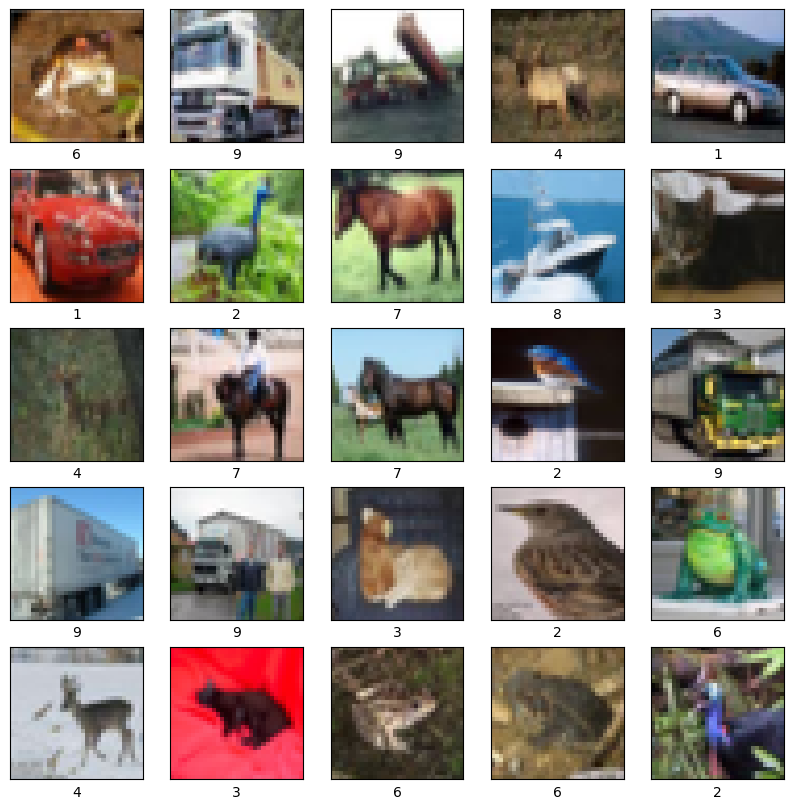

In [ ]:
import matplotlib.pyplot as plt

# Display sample images from the CIFAR-10 dataset
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(y_train[i][0])
plt.show()


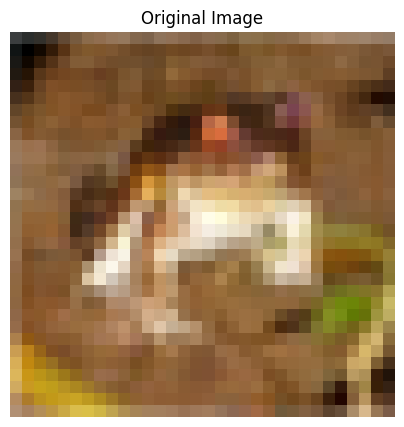

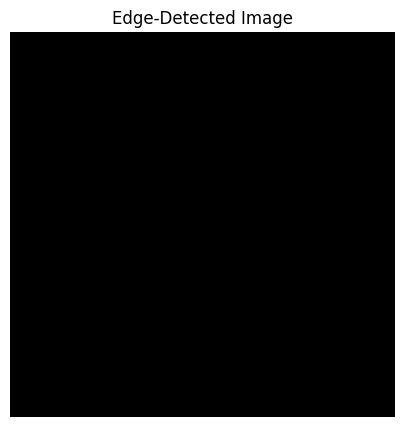

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load and display an example image from the CIFAR-10 dataset
sample_image = x_train[0]
plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.title("Original Image")
plt.axis('off')
plt.show()

# Convert the sample image to grayscale
gray_image = cv2.cvtColor(sample_image, cv2.COLOR_RGB2GRAY)

# Ensure the image is of data type np.uint8
gray_image = gray_image.astype(np.uint8)

# Apply edge detection using Canny method
edges = cv2.Canny(gray_image, threshold1=50, threshold2=150)

# Display the edge-detected image
plt.figure(figsize=(5, 5))
plt.imshow(edges, cmap='gray')
plt.title("Edge-Detected Image")
plt.axis('off')
plt.show()


In [ ]:
!mkdir train_data_dir
!mkdir test_data_dir

In [ ]:
import os

train_image_count = len(os.listdir(train_data_dir))
test_image_count = len(os.listdir(test_data_dir))

print(f"Number of images in train_data_dir: {train_image_count}")
print(f"Number of images in test_data_dir: {test_image_count}")


Number of images in train_data_dir: 240
Number of images in test_data_dir: 60


CNN

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models

# Define the paths to your train and test data folders
train_data_dir = '/content/train_data_dir'
test_data_dir = '/content/test_data_dir'

# Set the batch size and image dimensions
batch_size = 32
image_height = 32
image_width = 32

# Create an ImageDataGenerator for training data
train_datagen = ImageDataGenerator(
    rescale=1.0/255.0,  # Normalize pixel values to the range [0, 1]
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2  # Split data into training and validation sets
)

# Load and preprocess the training data
train_generator = train_datagen.flow_from_directory(
    train_data_dir,
    target_size=(image_height, image_width),
    batch_size=batch_size,
    class_mode='categorical',  # Change to 'binary' for binary classification
    subset='training'  # Use the training subset of data
)

# Load and preprocess the validation data
validation_generator = train_datagen.flow_from_directory(
    train_data_dir,
    target_size=(image_height, image_width),
    batch_size=batch_size,
    class_mode='categorical',  # Change to 'binary' for binary classification
    subset='validation'  # Use the validation subset of data
)

# Load and preprocess the test data
test_datagen = ImageDataGenerator(rescale=1.0/255.0)  # Only rescale for test data
test_generator = test_datagen.flow_from_directory(
    test_data_dir,
    target_size=(image_height, image_width),
    batch_size=batch_size,
    class_mode='categorical',  # Change to 'binary' for binary classification
    shuffle=False  # Do not shuffle test data
)

# Define the CNN model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')  # Assuming 10 classes for classification
])

# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',  # Use 'binary_crossentropy' for binary classification
              metrics=['accuracy'])

# Display a summary of the model architecture
model.summary()

# Train the model using the generators
history = model.fit(
    train_generator,
    epochs=10,  # Number of training epochs
    validation_data=validation_generator,
    verbose=1  # Set to 1 for progress updates, 0 to suppress output
)

# Optionally, save the trained model
model.save('trained_model.h5')

# Evaluate the model using the test data
test_loss, test_accuracy = model.evaluate(test_generator)

# Display the test accuracy
print(f'Test accuracy: {test_accuracy * 100:.2f}%')

Found 0 images belonging to 0 classes.
Found 0 images belonging to 0 classes.
Found 0 images belonging to 0 classes.
Model: "sequential_15"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_47 (Conv2D)          (None, 30, 30, 32)        896       
                                                                 
 max_pooling2d_35 (MaxPooli  (None, 15, 15, 32)        0         
 ng2D)                                                           
                                                                 
 conv2d_48 (Conv2D)          (None, 13, 13, 64)        18496     
                                                                 
 max_pooling2d_36 (MaxPooli  (None, 6, 6, 64)          0         
 ng2D)                                                           
                                                                 
 conv2d_49 (Conv2D)          (None, 4, 4, 64)          36928     
  

ValueError: Asked to retrieve element 0, but the Sequence has length 0